# Diagnostics: stationarity, autocorrelation, outliers

In [1]:
# Setup: install the toolkit when running on Google Colab, and a plotting style
import sys

if "google.colab" in sys.modules:
    %pip install -q "econts[book] @ git+https://github.com/hmorao95/econ-time-series-manual"

import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

Quick checks before modelling: is the series stationary (or which
transformation makes it so)? How persistent is it? Are there outliers that
will drive the results?

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss, zivot_andrews
from statsmodels.tools.sm_exceptions import InterpolationWarning
from econts import load

y = 100 * np.log(load("GDPC1")).loc[:"2019"]
dy = y.diff().dropna()
u = load("UNRATE").loc[:"2019"]

## ADF and KPSS together

In [3]:
def unit_root_table(series: dict[str, pd.Series]) -> pd.DataFrame:
    """ADF and KPSS p-values; `regression` is 'ct' (trend) or 'c' (constant)."""
    rows = {}
    for name, (s, reg) in series.items():
        adf_p = adfuller(s, regression=reg, autolag="AIC", result_object=True).pvalue
        with warnings.catch_warnings():  # KPSS p-values are bounded
            warnings.simplefilter("ignore", InterpolationWarning)
            kpss_p = kpss(s, regression=reg, nlags="auto", result_object=True).pvalue
        verdict = (
            "stationary"
            if adf_p < 0.05 and kpss_p > 0.05
            else "unit root"
            if adf_p > 0.05 and kpss_p < 0.05
            else "unclear"
        )
        rows[name] = {
            "ADF p (H0: unit root)": adf_p,
            "KPSS p (H0: stationary)": kpss_p,
            "verdict": verdict,
        }
    return pd.DataFrame(rows).T.infer_objects()


print(
    unit_root_table(
        {
            "log GDP (trend)": (y, "ct"),
            "GDP growth": (dy, "c"),
            "unemployment rate": (u, "c"),
        }
    ).round(3)
)

                   ADF p (H0: unit root)  KPSS p (H0: stationary)     verdict
log GDP (trend)                    0.627                    0.010   unit root
GDP growth                         0.000                    0.071  stationary
unemployment rate                  0.037                    0.033     unclear


```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.diagnostics import unit_root_table
```

Log GDP has a unit root, its growth rate is stationary. The unemployment
rate is the typical "unclear" case: both tests reject. It is very persistent
but bounded, a near-unit-root process; treat it as stationary in levels for
most macro work, and check that results survive using its first difference.

KPSS p-values are tabulated only between 0.01 and 0.10; values at those
bounds mean "at most 0.01" or "at least 0.10".

## Structural breaks

A break in the trend makes a stationary series look like a unit root.
Zivot–Andrews tests the unit root against a trend-stationary alternative
with one endogenous break, and estimates the break date.

In [4]:
stat, pval, crit, lags, bp = zivot_andrews(y.to_numpy(), regression="ct", autolag="AIC")
print(f"ZA stat {stat:.2f}, p = {pval:.2f}, break at {y.index[bp]:%Y-%m}")

ZA stat -3.83, p = 0.62, break at 1997-01


Here the test does not reject: one trend break is not enough to make US log
GDP trend-stationary.

## Autocorrelation

The ACF shows persistence; the PACF suggests the AR order.

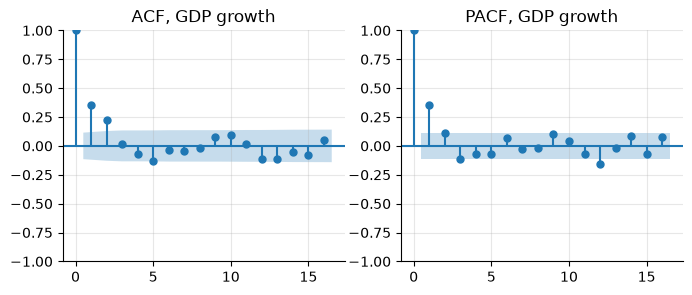

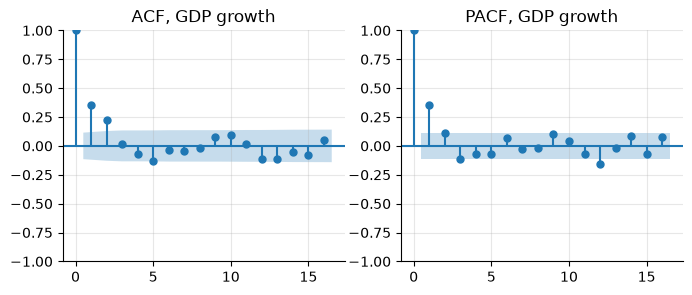

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
sm.graphics.tsa.plot_acf(dy, lags=16, ax=axes[0], title="ACF, GDP growth")
sm.graphics.tsa.plot_pacf(
    dy, lags=16, ax=axes[1], title="PACF, GDP growth", method="ywm"
)

The Ljung–Box test checks whether residuals (or a series) are white noise:

In [6]:
print(sm.stats.acorr_ljungbox(dy, lags=[4, 8], return_df=True).round(4))

   lb_stat  lb_pvalue
4  53.8564        0.0
8  59.7674        0.0


## Outliers

A robust z-score uses the rolling median and the median absolute deviation
(MAD), which outliers do not drag along.

In [7]:
def robust_outliers(s: pd.Series, window: int = 21, threshold: float = 4.0):
    """Flag points more than `threshold` robust SDs from the rolling median."""
    med = s.rolling(window, center=True, min_periods=window // 2).median()
    mad = (s - med).abs().rolling(window, center=True, min_periods=window // 2).median()
    z = (s - med) / (1.4826 * mad)  # 1.4826 * MAD = SD under normality
    return z.abs() > threshold


claims = load("ICSA")
flags = robust_outliers(np.log(claims))
print(claims[flags].loc["2020"].head())  # the March-April 2020 surge

date
2020-03-28    5946000.0
2020-04-04    6137000.0
2020-04-11    4869000.0
2020-04-18    4201000.0
2020-04-25    3446000.0
Name: ICSA, dtype: float64


```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.diagnostics import robust_outliers, winsorize
```

Then decide: **correct** a data error, **dummy** a genuine one-off (strike,
hurricane, lockdown), or **winsorize** when the outliers are noise:

In [8]:
dy_full = 100 * np.log(load("GDPC1")).diff().dropna()
lo, hi = dy_full.quantile([0.01, 0.99])
dy_wins = dy_full.clip(lo, hi)
print(
    dy_full.loc["2020"].round(2).tolist(), "->", dy_wins.loc["2020"].round(2).tolist()
)

# one pulse per quarter: the crash and the rebound have opposite signs,
# so a single 2020Q2-Q3 dummy would absorb neither (chapter 10)
covid = pd.DataFrame(0.0, index=dy_full.index, columns=["2020Q2", "2020Q3"])
covid.loc["2020-04-01", "2020Q2"] = 1.0
covid.loc["2020-07-01", "2020Q3"] = 1.0

[-1.33, -8.2, 7.48, 1.13] -> [-1.33, -1.99, 3.7, 1.13]


## Pitfalls

* Seasonal adjustment filters bias ADF tests toward **not** rejecting a unit
  root (Ghysels and Perron, 1993). With unadjusted data, add seasonal
  dummies to the test regression instead.
* Running the test on the full sample including 2020 makes many series look
  stationary (a huge mean-reverting spike) or not (a level shift).
* "Fail to reject" is not "accept": ADF cannot tell a unit root from a root
  of 0.95 in 60 years of quarterly data.

## Summary

* Run **ADF** (null: unit root) and **KPSS** (null: stationary) together.
  Conclusions are strongest when they agree.
* Include a trend in the test when the series trends (log GDP); omit it
  for growth rates and rates (unemployment).
* Unit-root tests have low power in short samples and are fooled by
  structural breaks. Use economics as well as p-values.

## Exercises

1. Run ADF and KPSS on log CPI (`CPIAUCSL`, with trend), on monthly CPI inflation (constant) and on the Portuguese 10-year yield (`IRLTLT01PTM156N`, constant), all ending in 2019. Which verdicts are clear and which are "unclear"?
2. Run Zivot–Andrews on log Portuguese real GDP (`CLVMNACSCAB1GQPT`, 1995–2019). Where does it place the break, does it reject the unit root, and does the date make economic sense?
3. Fit an AR(1) to quarterly US GDP growth (1947–2019) and apply the Ljung–Box test to its residuals at lags 4 and 8. Is one lag enough? Compare with what the PACF of GDP growth suggests.
4. Repeat the ADF and KPSS tests on the US unemployment rate over 1948 to the end of the sample instead of 1948–2019. Does including 2020 change the verdict, and in which direction would you expect a large, quickly reversed spike to push each test?